In [2]:
import pandas as pd
df = pd.read_csv('../data/Online Retail.csv', encoding='latin1')
df.head()
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [3]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%Y-%m-%d %H:%M')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 59.5 MB


In [5]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']
total_net_revenue = df['Revenue'].sum()
total_net_revenue

np.float64(9747747.934)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
 8   Revenue      541909 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 63.7 MB


In [7]:
df['Monthdesc'] = df['InvoiceDate'].dt.strftime('%Y-%m')  
df.groupby('Monthdesc')['Revenue'].sum()

Monthdesc
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     682680.510
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Name: Revenue, dtype: float64

In [8]:
df['Cancel_Ordercount'] = df['InvoiceNo'].str.startswith('C', na=True)   
df.groupby('Cancel_Ordercount')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   InvoiceNo          541909 non-null  str           
 1   StockCode          541909 non-null  str           
 2   Description        540455 non-null  str           
 3   Quantity           541909 non-null  int64         
 4   InvoiceDate        541909 non-null  datetime64[us]
 5   UnitPrice          541909 non-null  float64       
 6   CustomerID         406829 non-null  float64       
 7   Country            541909 non-null  str           
 8   Revenue            541909 non-null  float64       
 9   Monthdesc          541909 non-null  str           
 10  Cancel_Ordercount  541909 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(3), int64(1), str(5)
memory usage: 71.9 MB


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   InvoiceNo          541909 non-null  str           
 1   StockCode          541909 non-null  str           
 2   Description        540455 non-null  str           
 3   Quantity           541909 non-null  int64         
 4   InvoiceDate        541909 non-null  datetime64[us]
 5   UnitPrice          541909 non-null  float64       
 6   CustomerID         406829 non-null  float64       
 7   Country            541909 non-null  str           
 8   Revenue            541909 non-null  float64       
 9   Monthdesc          541909 non-null  str           
 10  Cancel_Ordercount  541909 non-null  bool          
dtypes: bool(1), datetime64[us](1), float64(3), int64(1), str(5)
memory usage: 71.9 MB


In [11]:
real_orders = df[~df['Cancel_Ordercount']]
real_orders.groupby('Monthdesc')['InvoiceNo'].nunique()

Monthdesc
2010-12    1699
2011-01    1216
2011-02    1174
2011-03    1665
2011-04    1504
2011-05    1848
2011-06    1683
2011-07    1657
2011-08    1459
2011-09    1994
2011-10    2275
2011-11    3021
2011-12     869
Name: InvoiceNo, dtype: int64

In [12]:
monthly_revenue = df.groupby('Monthdesc')['Revenue'].sum()
monthly_orders = real_orders.groupby('Monthdesc')['InvoiceNo'].nunique()
monthly_aov = monthly_revenue / monthly_orders

In [13]:
monthly_aov

Monthdesc
2010-12    440.822260
2011-01    460.526530
2011-02    424.244165
2011-03    410.370619
2011-04    327.930267
2011-05    391.414237
2011-06    410.649507
2011-07    411.164823
2011-08    467.909877
2011-09    511.377945
2011-10    470.639415
2011-11    483.865028
2011-12    499.042589
dtype: float64

In [14]:
import matplotlib.pyplot as plt

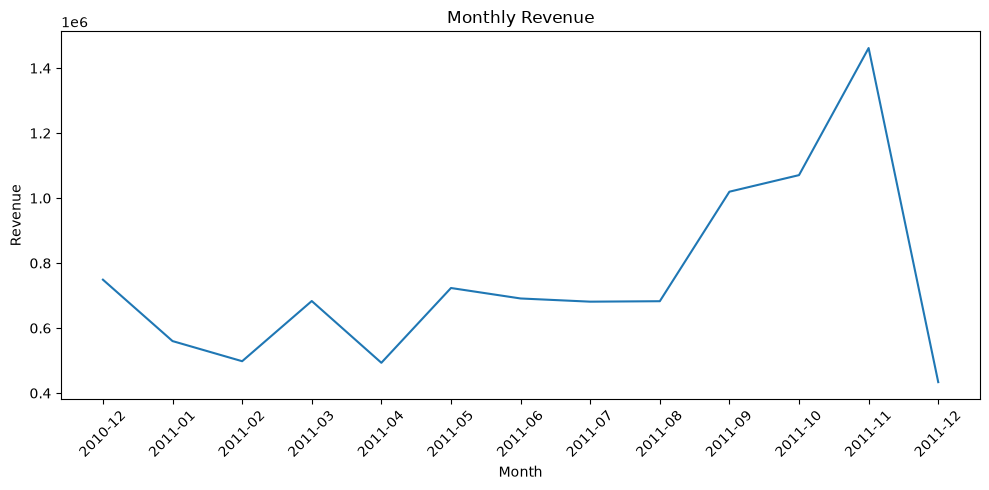

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [16]:
real_customer = df[df['CustomerID'].notna()] 
top_customers_by_rev = real_customer.groupby('CustomerID')['Revenue'].sum().nlargest(10)

In [17]:
top_customers_by_rev

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187482.17
14911.0    132572.62
12415.0    123725.45
14156.0    113384.14
17511.0     88125.38
16684.0     65892.08
13694.0     62653.10
15311.0     59419.34
Name: Revenue, dtype: float64

In [18]:
customer_orders = real_orders.groupby('CustomerID')['InvoiceNo'].nunique()
import numpy as np
customer_type = np.where(customer_orders > 1, 'repeat', 'one-time')

In [19]:
real_customer['CustomerID'].nunique()

4372

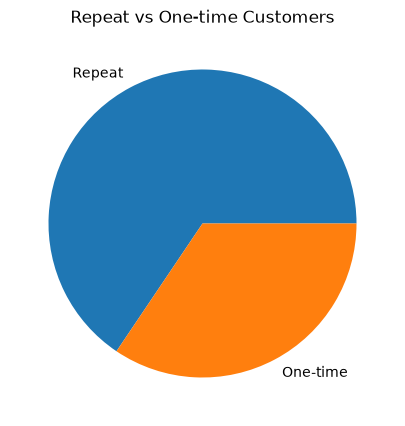

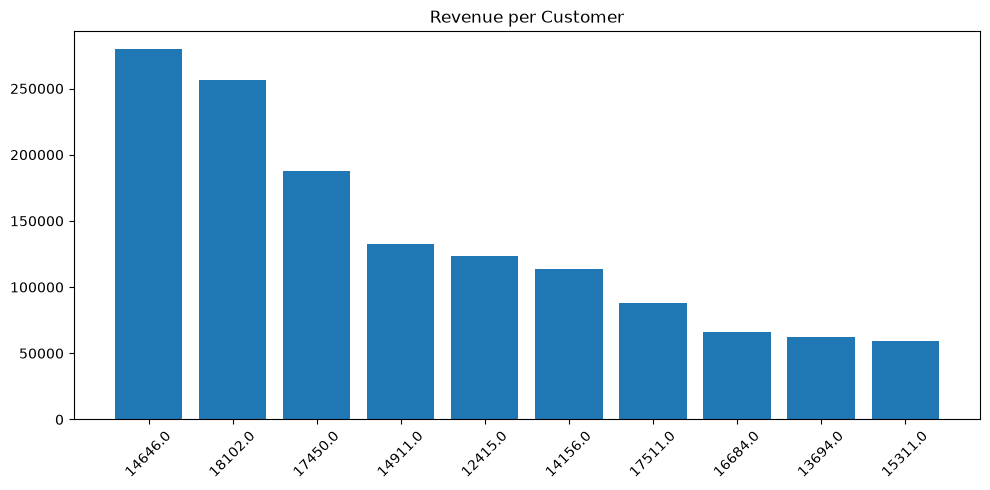

In [20]:
repeat_count = (customer_type == 'repeat').sum()
one_time_count = (customer_type == 'one-time').sum()
repeat_buyer_ratio = repeat_count / one_time_count

plt.figure(figsize=(10, 5))
plt.pie([repeat_count, one_time_count], labels=['Repeat', 'One-time'])
plt.title("Repeat vs One-time Customers")
plt.show()

plt.figure(figsize=(10, 5))
plt.title("Revenue per Customer")
plt.bar(top_customers_by_rev.index.astype(str), top_customers_by_rev)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
reindex_customerfull = real_customer['CustomerID'].unique()
comprehensive_customer_orders = customer_orders.reindex(reindex_customerfull).fillna(0)

In [22]:
comprehensive_customer_orders

CustomerID
17850.0    34.0
13047.0    10.0
12583.0    15.0
13748.0     5.0
15100.0     3.0
           ... 
13436.0     1.0
15520.0     1.0
13298.0     1.0
14569.0     1.0
12713.0     1.0
Name: InvoiceNo, Length: 4372, dtype: float64

In [23]:
customer_type_revised = np.where(comprehensive_customer_orders > 1, 'repeat', 'one-time')
repeat_count = (customer_type_revised == 'repeat').sum()
one_time_count = (customer_type_revised == 'one-time').sum()
repeat_buyer_ratio = repeat_count / one_time_count

In [24]:
repeat_buyer_ratio

np.float64(1.8631303208906351)

In [25]:
repeat_count / (repeat_count + one_time_count) * 100

np.float64(65.07319304666058)

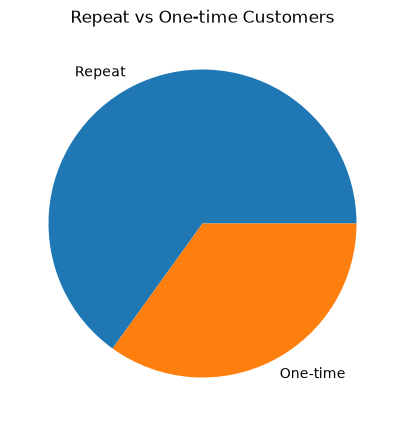

In [26]:
plt.figure(figsize=(10, 5))
plt.pie([repeat_count, one_time_count], labels=['Repeat', 'One-time'])
plt.title("Repeat vs One-time Customers")
plt.show()

In [27]:
revenue = df['UnitPrice'] * df['Quantity']
revenue_by_product = revenue.groupby(df['StockCode']).sum()
revenue_by_product_top10 = revenue_by_product.nlargest(10)

In [28]:
revenue_by_product_top10 #problem with DOT and POST

StockCode
DOT       206245.48
22423     164762.19
47566      98302.98
85123A     97894.50
85099B     92356.03
23084      66756.59
POST       66230.64
22086      63791.94
84879      58959.73
79321      53768.06
dtype: float64

In [29]:
revenue_clean_df = df[~df['StockCode'].str.contains(r'POST|DOT', na=False)]

In [30]:
revenue = revenue_clean_df['UnitPrice'] * revenue_clean_df['Quantity']
revenue_by_product = revenue.groupby(revenue_clean_df['StockCode']).sum()
revenue_by_product_top10 = revenue_by_product.nlargest(10)
revenue_by_product_top10

StockCode
22423     164762.19
47566      98302.98
85123A     97894.50
85099B     92356.03
23084      66756.59
22086      63791.94
84879      58959.73
79321      53768.06
22502      51041.37
22197      50987.47
dtype: float64

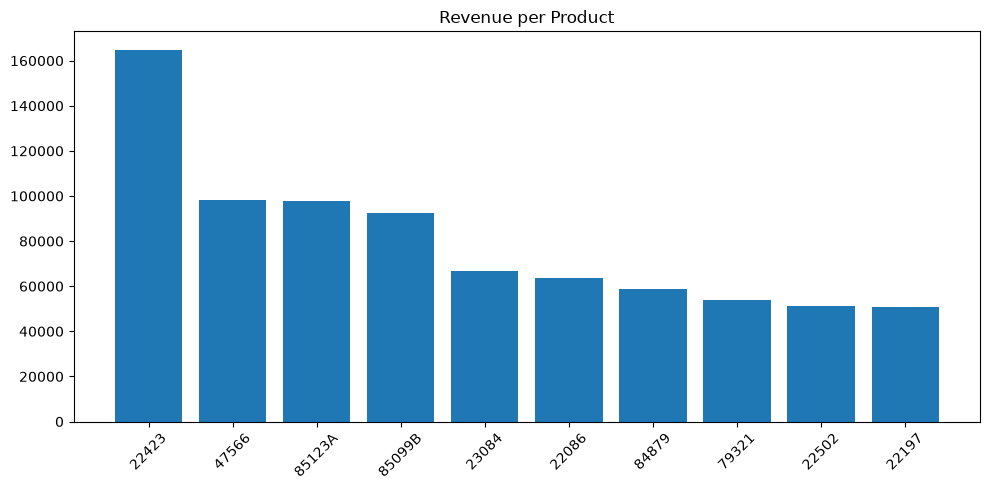

In [31]:
plt.figure(figsize=(10, 5))
plt.title("Revenue per Product")
plt.bar(revenue_by_product_top10.index.astype(str), revenue_by_product_top10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

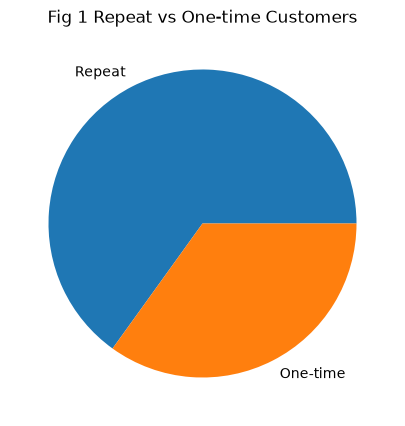

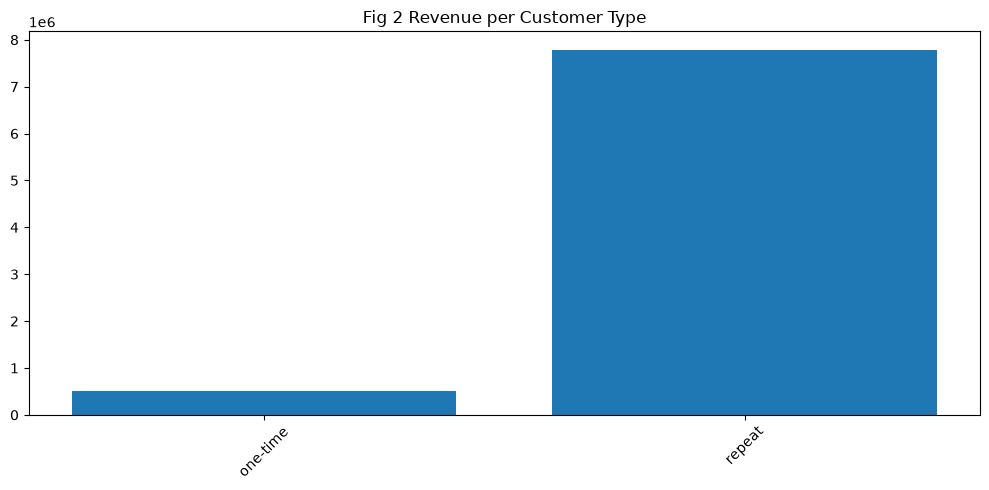

In [32]:
#our fusebox went down. reloading pd
import pandas as pd
Rev_Customer_Summary = pd.DataFrame({
    'Metric': ['Repeat Count', 'One-Time Count', 'Repeat Buyer Ratio'],
    'Value': [repeat_count, one_time_count, repeat_buyer_ratio]
})
plt.figure(figsize=(10, 5))
plt.pie([repeat_count, one_time_count], labels=['Repeat', 'One-time'])
plt.title("Fig 1 Repeat vs One-time Customers")
plt.show()
top_customers_by_rev_all = real_customer.groupby('CustomerID')['Revenue'].sum()
comprehensive_customer_orders_fixed = top_customers_by_rev_all.reindex(reindex_customerfull).fillna(0)
fig_2_core = comprehensive_customer_orders_fixed.groupby(customer_type_revised).sum()
plt.figure(figsize=(10, 5))
plt.title("Fig 2 Revenue per Customer Type")
plt.bar(fig_2_core.index.astype(str), fig_2_core)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Product Analysis

The top 10 products by revenue are mostly home decoration and gifts such as cake stands, decorative lights, and ornaments. It is hard to say that these are everyday essentials. This is consistent with the November revenue peak found in the revenue analysis, suggesting that a lot of the demand is seasonal and the business relies heavily on pre-holiday gifts and decor purchases rather than steady year-round sales. 

Cross-validated against the SQL version also caught an aggregation bug in the original query (documented in the project log and the SQL file itself).

Repeat Purchase Analysis

About 65% of customers with a valid ID made more than one purchase. The repeat buyers account for roughly £7.6 million of net revenue compared to about £0.5 million from one-time buyers. This indicates that retention is what's driving most of the revenue here.

A retention-focused strategy like loyalty incentives or targeted campaigns is likely to have more impact than efforts to acquire new one-time customers.